<a href="https://colab.research.google.com/github/Lupo6789/tesi_scacchi/blob/main/01%20Pulizia%20dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In questa prima cella ho importato il dataset grezzo che contiene le partite estratte da Lichess

In [ ]:
import pandas as pd

#Viene letto il dataset
df = pd.read_csv('games.csv')
print(f"Punto di partenza: {df.shape[0]} partite e {df.shape[1]} colonne.")

Punto di partenza: 20058 partite e 16 colonne.


Qui elimino le partite uguali ripetute nel dataset perchè ovviamente non vanno ad aggiungere alcuna informazione utile, per farlo elimino le partite che hanno lo stesso 'id'. MAntengo solo la prima occorrenza tra queste. : Se due righe identiche finissero accidentalmente l'una nel Training Set e l'altra nel Test Set, il modello si limiterebbe a "memorizzare" l'esito di una scacchiera già vista, andando a falsare la accuratezza in fase di valutazione.

In [ ]:
# Conto i duplicati prima di agire
id_ripetuti = df.duplicated(subset=['id']).sum()
print(f"Trovati {id_ripetuti} ID duplicati.")

# Elimino i duplicati tenendo solo la prima occorrenza
df = df.drop_duplicates(subset=['id'], keep='first')
print(f"Dopo la pulizia duplicati restano: {df.shape[0]} partite.")

Trovati 945 ID duplicati.
Dopo la pulizia duplicati restano: 19113 partite.


è più efficace una classificazione binaria, a causa delle patte si creerebbe la cosidetta "class imbalance". La loro assenza inoltre libera il dataset dal rumore statistico dovuto alle variabili comportamentali dei goocatori

In [ ]:
# Conto le patte
patte = (df['winner'] == 'draw').sum()
print(f"Trovate {patte} partite finite in parità.")

# Filtro il dataset escludendo le patte
df = df[df['winner'] != 'draw']
print(f"Dopo l'esclusione delle patte restano: {df.shape[0]} partite per il modello binario.")

Trovate 888 partite finite in parità.
Dopo l'esclusione delle patte restano: 18225 partite per il modello binario.


Viene verificato che uno stesso giocatore non monopolizzi completamente il dataset giocando troppe partite, vengono rimosse le colonne turns e victory status per evitare il data leakage (non voglio informazioni dal futuro), scarto created_at e last_move_at perchè superflui ai fini dello studio.

In [ ]:
# 1. Controllo quante partite gioca ciascun giocatore
tutti_i_giocatori = pd.concat([df['white_id'], df['black_id']])
partite_per_giocatore = tutti_i_giocatori.value_counts()
print(f"Giocatori unici totali: {len(partite_per_giocatore)}")
print("\nI 5 giocatori con più partite nel dataset:")
print(partite_per_giocatore.head(5))

# 2. Rimozione definitiva del Data Leakage e dei Timestamp
colonne_da_rimuovere = ['turns', 'victory_status', 'created_at', 'last_move_at']
df = df.drop(columns=colonne_da_rimuovere)
print(f"\nRimozione completata. Struttura finale: {df.shape[0]} righe e {df.shape[1]} colonne.")

# 3. Salvo il dataset pulito per il prossimo notebook
df.to_csv('games_cleaned.csv', index=False)
print("Il file 'games_cleaned.csv' è stato creato e salvato su Colab")

Giocatori unici totali: 15127

I 5 giocatori con più partite nel dataset:
dipset             51
fandm-lancaster    50
blazingdragon      49
robixy             48
kevchod            48
Name: count, dtype: int64

Rimozione completata. Struttura finale: 18225 righe e 12 colonne.
Il file 'games_cleaned.csv' è stato creato e salvato su Colab


Il dataset viene suddivisio in 'Training Set' e 'Test Set', (80%-20%) prima di ogni operazione di feature engeneering. Utilizzo il campionamento stratificato 'stratify' sulla variabile target, ovvero 'winner', affinchè le proporzioni di vittoria siano le stesse per entrambi i sottocampioni.
Il Test Set non verrà più analizzato né manipolato fino alla fase finale di validazione dei modelli.

In [ ]:
from sklearn.model_selection import train_test_split

print("DIVISIONE DEL DATASET (TRAIN / TEST)")

#Suddivisione 80% Train / 20% Test con stratificazione sul target
df_train, df_test = train_test_split(df, test_size=0.2, random_state=42, stratify=df['winner'])

print(f"Dataset di Addestramento (Train): {df_train.shape[0]} partite")
print(f"Dataset di Valutazione (Test): {df_test.shape[0]} partite")

#Salvataggio dei due file separati
df_train.to_csv('train_cleaned.csv', index=False)
df_test.to_csv('test_cleaned.csv', index=False)

print("\nOperazione completata. I file 'train_cleaned.csv' e 'test_cleaned.csv' sono pronti.")

DIVISIONE DEL DATASET (TRAIN / TEST)
Dataset di Addestramento (Train): 14580 partite
Dataset di Valutazione (Test): 3645 partite

Operazione completata. I file 'train_cleaned.csv' e 'test_cleaned.csv' sono pronti.


Riguarda solo il training set e serve per validare i dati di base, vengono quindi visualizzate la distribuzione della variabile target (ovvero vittoria bianco o nero), le curve di densità dei punteggiu Elo (rating), le cadenze di gioco prevalenti e la correlazione tra la differenza di rating e la percentuale di vittoria.

--- INIZIO ANALISI ESPLORATIVA (EDA) SUL SOLO TRAIN SET ---


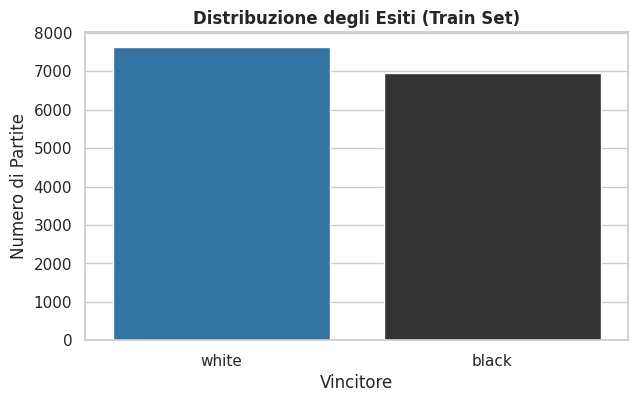

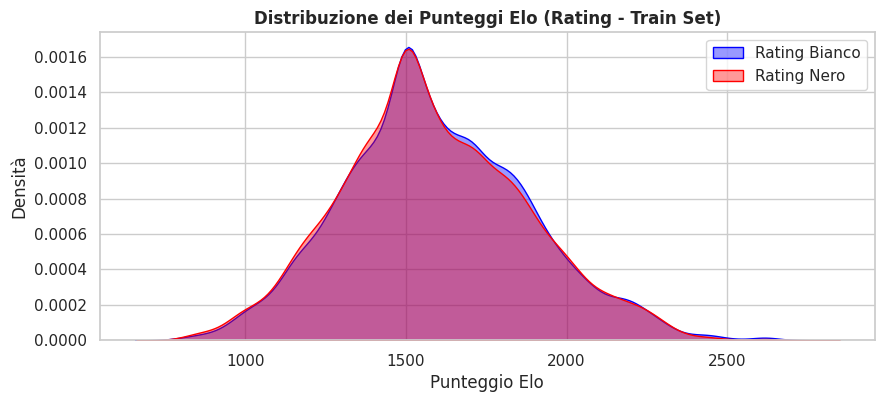

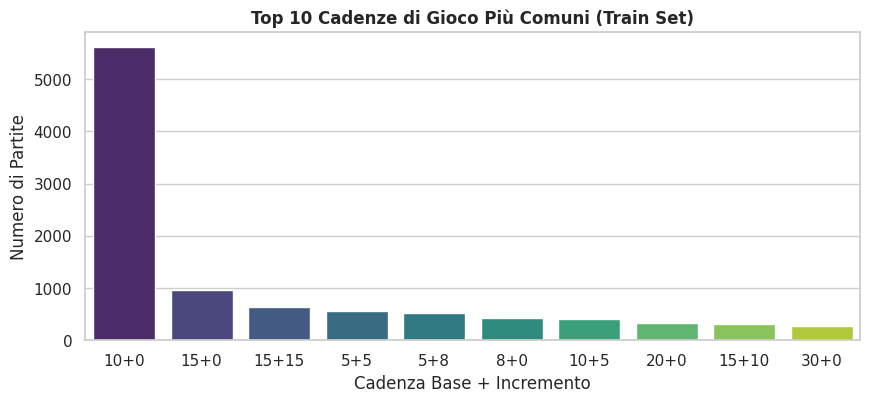

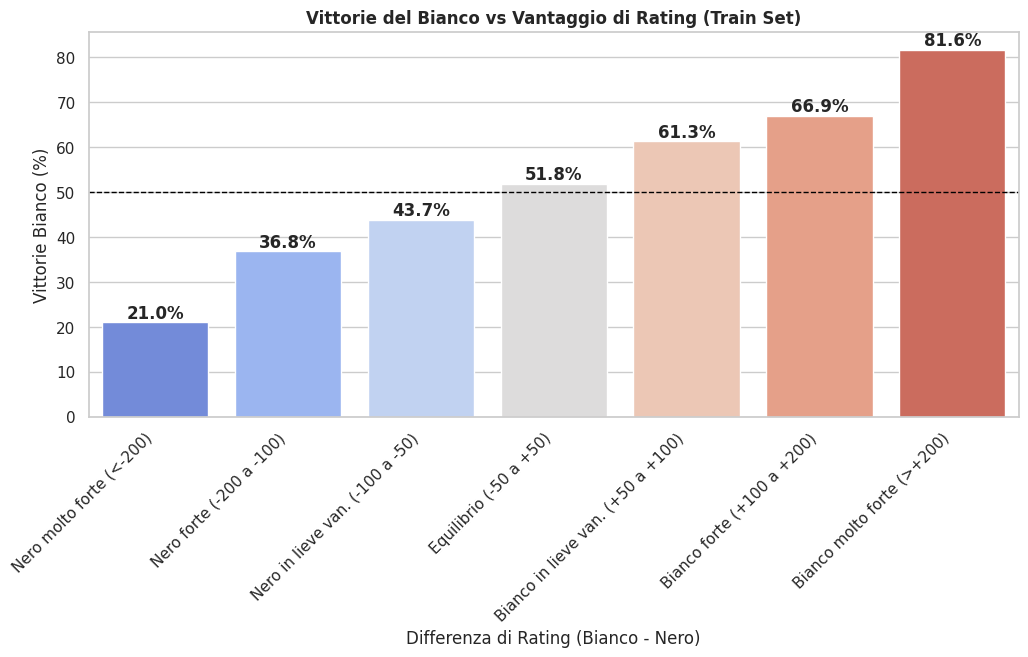

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

#Imposto lo stile dei grafici
sns.set_theme(style="whitegrid")

print("--- INIZIO ANALISI ESPLORATIVA (EDA) SUL SOLO TRAIN SET ---")

# Per sicurezza, ci assicuriamo di lavorare su una copia indipendente
df_train = df_train.copy()

# 1. Distribuzione degli Esiti
plt.figure(figsize=(7, 4))
sns.countplot(data=df_train, x='winner', hue='winner', palette=['#1f77b4', '#333333'], legend=False)
plt.title("Distribuzione degli Esiti (Train Set)", fontsize=12, fontweight='bold')
plt.xlabel("Vincitore")
plt.ylabel("Numero di Partite")
plt.show()

# 2. Distribuzione dei Rating
plt.figure(figsize=(10, 4))
sns.kdeplot(df_train['white_rating'], fill=True, color="blue", label="Rating Bianco", alpha=0.4)
sns.kdeplot(df_train['black_rating'], fill=True, color="red", label="Rating Nero", alpha=0.4)
plt.title("Distribuzione dei Punteggi Elo (Rating - Train Set)", fontsize=12, fontweight='bold')
plt.xlabel("Punteggio Elo")
plt.ylabel("Densità")
plt.legend()
plt.show()

# 3. Distribuzione delle Cadenze di Gioco (Top 10)
plt.figure(figsize=(10, 4))
top_cadenze = df_train['increment_code'].value_counts().head(10)
sns.barplot(x=top_cadenze.index, y=top_cadenze.values, hue=top_cadenze.index, palette="viridis", legend=False)
plt.title("Top 10 Cadenze di Gioco Più Comuni (Train Set)", fontsize=12, fontweight='bold')
plt.xlabel("Cadenza Base + Incremento")
plt.ylabel("Numero di Partite")
plt.show()

# 4. Percentuale di Vittorie del Bianco in funzione della Differenza di Rating
df_train['rating_diff_temp'] = df_train['white_rating'] - df_train['black_rating']

bins = [-np.inf, -200, -100, -50, 50, 100, 200, np.inf]
labels = ['Nero molto forte (<-200)', 'Nero forte (-200 a -100)', 'Nero in lieve van. (-100 a -50)',
          'Equilibrio (-50 a +50)', 'Bianco in lieve van. (+50 a +100)', 'Bianco forte (+100 a +200)', 'Bianco molto forte (>+200)']

df_train['rating_fascia'] = pd.cut(df_train['rating_diff_temp'], bins=bins, labels=labels)

vittorie_bianco = df_train[df_train['winner'] == 'white'].groupby('rating_fascia', observed=False).size()
totale_fascia = df_train.groupby('rating_fascia', observed=False).size()
win_rates = (vittorie_bianco / totale_fascia) * 100

plt.figure(figsize=(12, 5))
ax = sns.barplot(x=win_rates.index, y=win_rates.values, hue=win_rates.index, palette="coolwarm", legend=False)
plt.title("Vittorie del Bianco vs Vantaggio di Rating (Train Set)", fontsize=12, fontweight='bold')
plt.xlabel("Differenza di Rating (Bianco - Nero)")
plt.ylabel("Vittorie Bianco (%)")
plt.axhline(50, color='black', linestyle='--', linewidth=1)
plt.xticks(rotation=45, ha='right')

for i, v in enumerate(win_rates.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha='center', fontweight='bold')

plt.show()

# Rimuoviamo le colonne temporanee
df_train = df_train.drop(columns=['rating_diff_temp', 'rating_fascia'])